# 1) Lectura de Datos

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_excel("Datos1D.xlsx")
print(f'Tamaño del Dataset: {df.shape}')
df.head()

Tamaño del Dataset: (1000, 2)


,ingresos,consumo
0,44.617090,9.720475
1,73.430827,12.340257
2,5.010866,1.535624
3,33.721594,7.879812
4,18.941810,4.721109


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ingresos  1000 non-null   float64
 1   consumo   1000 non-null   float64
dtypes: float64(2)
memory usage: 15.8 KB


<Axes: >

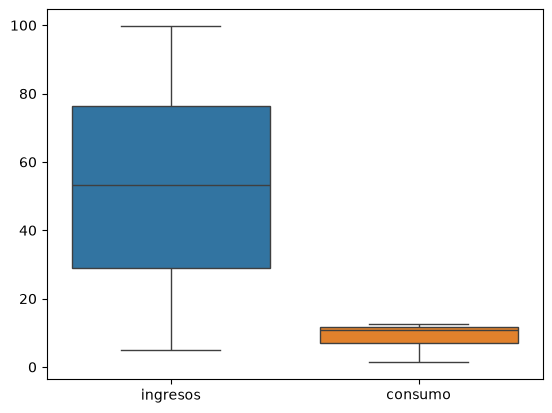

In [4]:
sns.boxplot(df)

## Variables

- El dataset posee un total de 1000 datos, sin datos nulos ni outliers
- Posee 2 variables: ingresos(entrada) y consumo(salida)

Text(0, 0.5, 'Consumo')

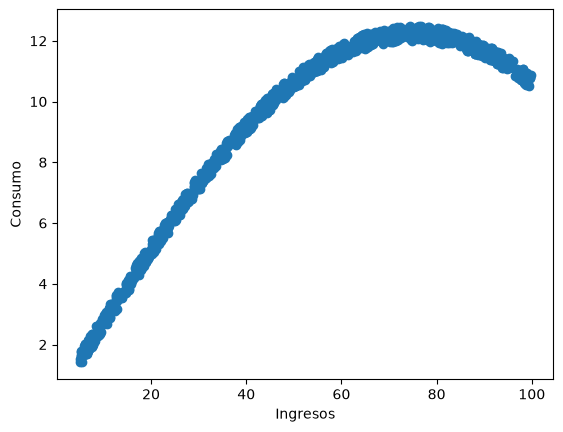

In [5]:
plt.scatter(df['ingresos'], df['consumo'])

plt.xlabel("Ingresos")
plt.ylabel("Consumo")

# 2) Modelo Polinomial

## Matriz de Características $X$

Para r = 7, con el numero de datos n=1000 la matriz de características tiene una dimension de $X^{1000 \times 7}$

In [6]:
#matriz de características
r = 7
n = 1000
X = np.empty((n, r+1))
for j in range(0, r+1):
    for i in range(0, n):
        X[i][j] = (df['ingresos'].iloc[i])**j

Y = np.empty((n, 1))
for i in range(0, n):
    Y[i] = df['consumo'].iloc[i]

La forma de la matriz de características es: 

$$
X = \begin{pmatrix}
1 & x_1 & x_1^{2} & \cdots  & x_{1}^{r} \\
1 & x_2 & x_2^{2} & \cdots  & x_{2}^{r} \\
\vdots  &\vdots  & \vdots   & \ddots   & \vdots  \\
1 & x_n  & x_n^{2} & \cdots  & x_{n}^{r}
\end{pmatrix}^{n \times (r+1)}
$$

# Matriz de Coeficientes Óptimos
- Se agarran los primeros 10 datos para el entrenamiento

In [7]:
X_train = X[:10]
Y_train = Y[:10]

X_test = X[10:]
Y_test = Y[10:]

print(Y_train)
print(np.shape(X_test))

[[ 9.72047465]
 [12.34025685]
 [ 1.53562405]
 [ 7.87981243]
 [ 4.72110866]
 [ 3.53707932]
 [ 5.9430482 ]
 [ 8.58663037]
 [ 9.47095526]
 [11.14076718]]
(990, 8)


In [8]:
#Vector de Coeficientes

W = np.linalg.inv(X_train.T @ X_train) @ (X_train.T @ Y_train)
print(W)

[[-3.08000976e+00]
 [ 1.70152314e+00]
 [-2.22240832e-01]
 [ 1.60427900e-02]
 [-6.09934581e-04]
 [ 1.24711394e-05]
 [-1.29446931e-07]
 [ 5.33234606e-10]]


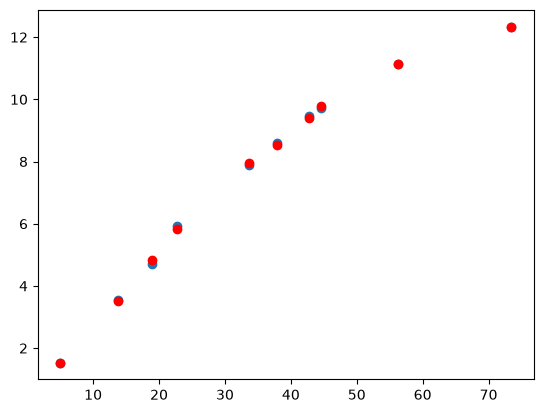

In [9]:
h_1 = X_train @ W
plt.scatter(X_train[:, 1], Y_train)
plt.scatter(X_train[:, 1], h_1, color = 'red')
plt.show()

Emplear un grado polinómico tan alto en el entrenamiento, el cual posee pocos datos comparado con el total, genera un sobreajuste. La función hipótesis se vuelve muy compleja lo que le permite pasar muy cerca de los puntos de entrenamiento.

El problema es que al emplear la función hipótesis en los datos de testeo (muchos más) la aproximación falla, debido a que se adaptó única y forzosamente a los datos de entrenamiento

# Función de Costo para distintos $r$

r = 7,  W = [[-3.08000976e+00]
 [ 1.70152314e+00]
 [-2.22240832e-01]
 [ 1.60427900e-02]
 [-6.09934581e-04]
 [ 1.24711394e-05]
 [-1.29446931e-07]
 [ 5.33234606e-10]]
r = 6,  W = [[ 2.10697317e+00]
 [-3.66227243e-01]
 [ 6.38265921e-02]
 [-2.98603591e-03]
 [ 6.87146513e-05]
 [-7.73866977e-07]
 [ 3.37818580e-09]]
r = 5,  W = [[ 7.76649710e-01]
 [ 9.68855471e-02]
 [ 1.26350682e-02]
 [-4.44228360e-04]
 [ 6.16226038e-06]
 [-3.13620691e-08]]
r = 4,  W = [[ 2.92917861e-01]
 [ 2.39212690e-01]
 [ 7.17482191e-04]
 [-3.99039563e-05]
 [ 2.20706919e-07]]
r = 3,  W = [[ 1.61019643e-01]
 [ 2.67716226e-01]
 [-9.08879467e-04]
 [-6.53707494e-06]]
r = 2,  W = [[-0.02459958]
 [ 0.29268712]
 [-0.00168523]]
r = 1,  W = [[1.7817173 ]
 [0.16353952]]


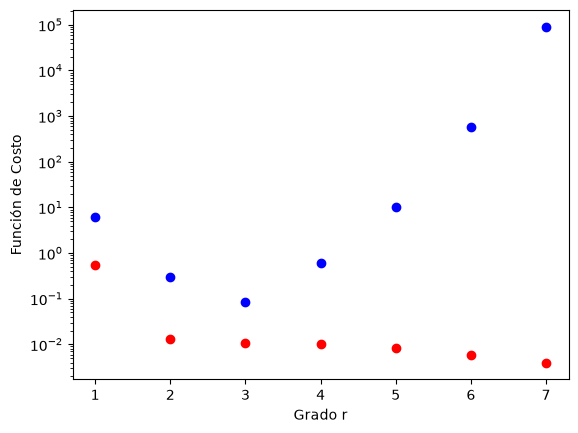

In [12]:
n_train = 10
n_test = 990

for i in range(r, 0, -1):
   
    X_train_r = X_train[:, :i+1]
    W_r = np.linalg.inv(X_train_r.T @ X_train_r) @ (X_train_r.T @ Y_train)

    # Para el conjunto de datos de entrenamiento
    h_train = X_train_r @ W_r
    J_train = 1/n_train * np.sum( (h_train - Y_train)**2 )

    # Para el conjunto de datos de testeo
    X_test_r = X_test[:, :i+1]
    
    h_test = X_test_r @ W_r
    J_test = 1/n_test * np.sum( (h_test - Y_test)**2 )

    print(f"r = {i},  W = {W_r}")
    
    plt.scatter(i, J_train, color = 'red')
    plt.scatter(i, J_test, color = 'blue')

plt.yscale('log')
plt.xlabel('Grado r')
plt.ylabel('Función de Costo')
plt.show()
